In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/Users/jannoelvero/Documents/amazon_uk_project/data/raw/amz_uk_price_prediction_dataset.csv"
)

In [2]:
import os

os.getcwd()

'/Users/jannoelvero/Documents/Ironhack/week_5/day_1/lab-eda-univariate'

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.shape

(2443651, 9)

In [5]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

In [6]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.dtypes

uid                    int64
asin                     str
title                    str
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category                 str
dtype: object

In [9]:
category_frequency = df["category"].value_counts()

category_frequency

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [10]:
top_5_categories = category_frequency.head(5)

top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [11]:
## Part 1: Understanding Product Categories

### Business Question

What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?


Object `frequency` not found.


In [12]:
category_frequency = df["category"].value_counts()

In [13]:
top_5_categories = category_frequency.head(5)

top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [14]:
#Finding: Sports & Outdoors clearly has the highest listing frequency, with 836,265 products. The remaining four categories each have approximately 19,000 listings. This shows a substantial concentration of product listings in Sports & Outdoors compared with the other leading categories.

In [15]:
##Visualizations**:
    # Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    # For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?


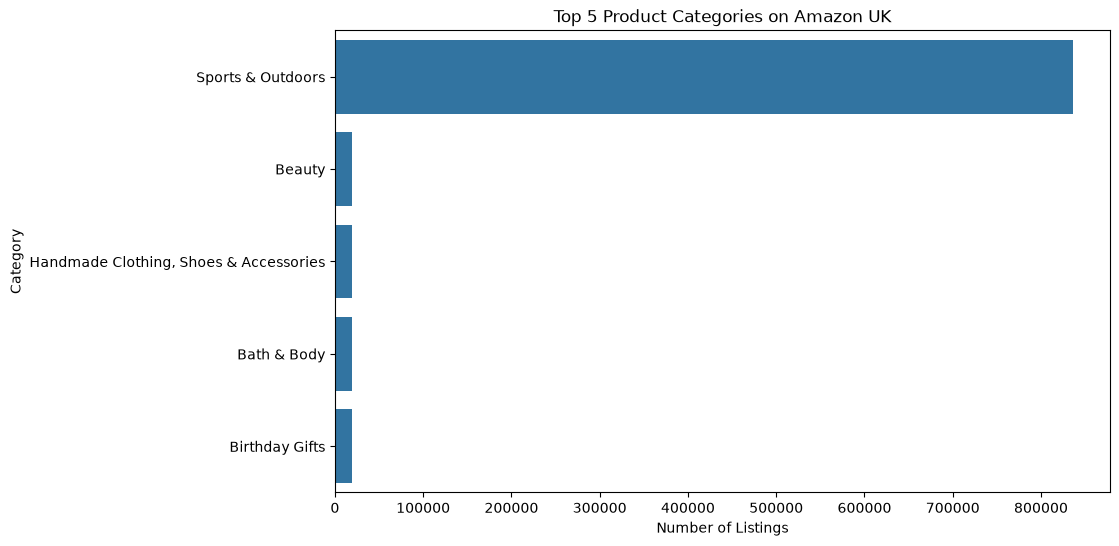

In [16]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_5_categories.values,
    y=top_5_categories.index
)

plt.title("Top 5 Product Categories on Amazon UK")
plt.xlabel("Number of Listings")
plt.ylabel("Category")

plt.show()

In [17]:
# Finding: The bar chart shows a substantial imbalance in listing frequency. Sports & Outdoors contains far more listings than any of the other top categories. The remaining leading categories have considerably smaller and relatively similar listing counts. This indicates a strong concentration of products within Sports & Outdoors in this dataset.

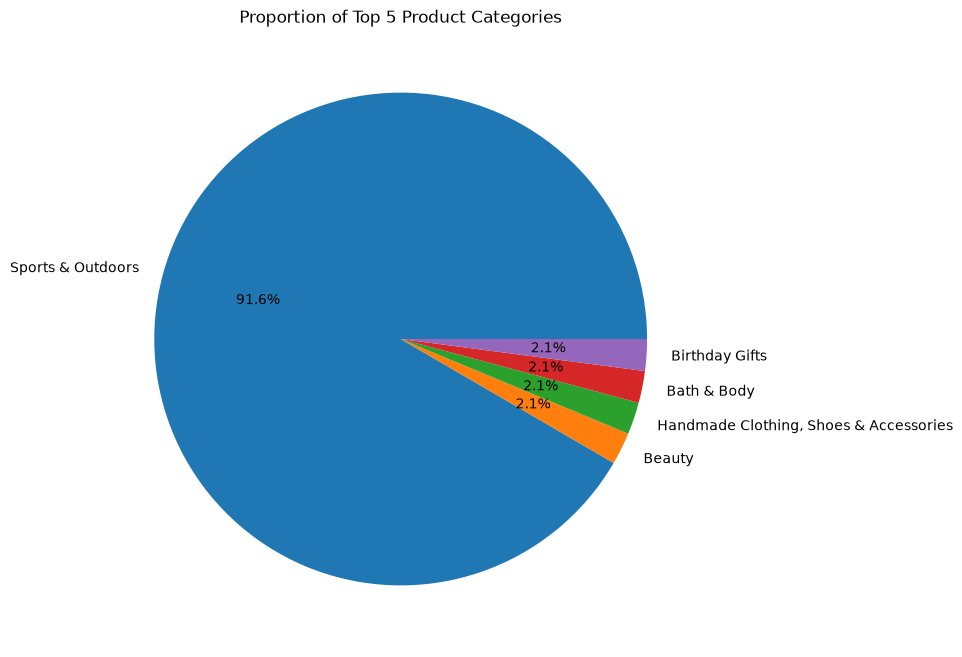

In [18]:
plt.figure(figsize=(8, 8))

plt.pie(
    top_5_categories.values,
    labels=top_5_categories.index,
    autopct="%1.1f%%"
)

plt.title("Proportion of Top 5 Product Categories")

plt.show()

In [19]:
# The percentages in this pie chart represent the proportions among the top five categories only, not among all 296 categories.

# Based on counts, Sports & Outdoors represents about 91.6 percent of the listings among these top five categories.

In [20]:
### Part 2: Delving into Product Pricing

#Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

In [21]:
# **Measures of Centrality**:
    # Calculate the mean, median, and mode for the `price` of products.
    # What's the average price point of products listed? How does this compare with the most common price point (mode)?

mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()[0]

print("Mean Price:", round(mean_price, 2))
print("Median Price:", round(median_price, 2))
print("Mode Price:", round(mode_price, 2))

Mean Price: 89.24
Median Price: 19.09
Mode Price: 9.99


In [22]:
# Finding: The average product price is £89.24, while the median price is much lower at £19.09 and the most common price is £9.99. The large difference between the mean and median suggests that the price distribution is positively skewed. Most products are concentrated at lower price points, while a smaller number of very expensive products increase the overall average price.

In [23]:
# Measures of Dispersion**:
    # Determine the variance, standard deviation, range, and interquartile range for product `price`.
    # How varied are the product prices? Are there any indicators of a significant spread in prices?

price_variance = df["price"].var()
price_std = df["price"].std()

price_range = df["price"].max() - df["price"].min()

q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
price_iqr = q3 - q1

print("Variance:", round(price_variance, 2))
print("Standard Deviation:", round(price_std, 2))
print("Range:", round(price_range, 2))
print("Q1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("IQR:", round(price_iqr, 2))

Variance: 119445.49
Standard Deviation: 345.61
Range: 100000.0
Q1: 9.99
Q3: 45.99
IQR: 36.0


In [24]:
# Finding: Product prices show substantial variation. The standard deviation of £345.61 is considerably higher than the mean price of £89.24, indicating a wide spread in prices. The total price range is £100,000, suggesting that the dataset contains extremely high priced products. However, the interquartile range is only £36, with the middle 50 percent of products priced between £9.99 and £45.99. This indicates that most products are concentrated at relatively low price points, while a small number of extremely expensive products create the large overall spread.

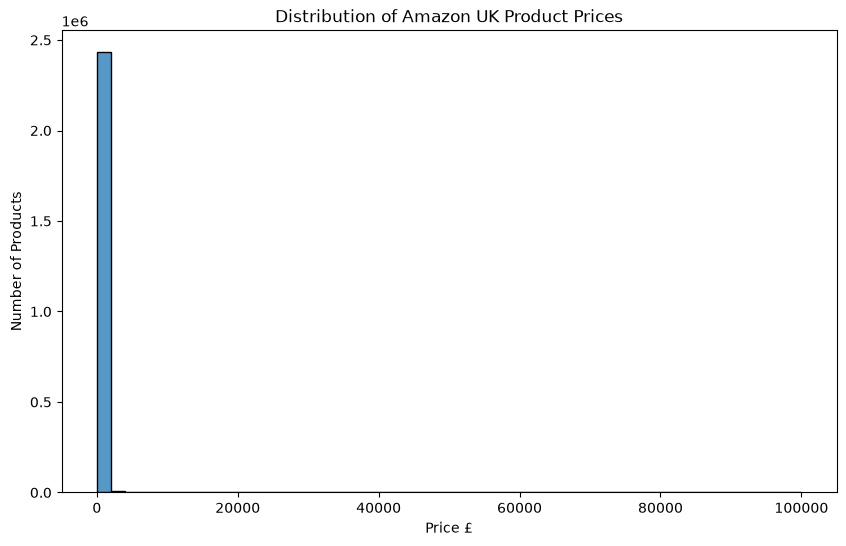

In [25]:
#**Visualizations**:
    # Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    # Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="price",
    bins=50
)

plt.title("Distribution of Amazon UK Product Prices")
plt.xlabel("Price £")
plt.ylabel("Number of Products")

plt.show()

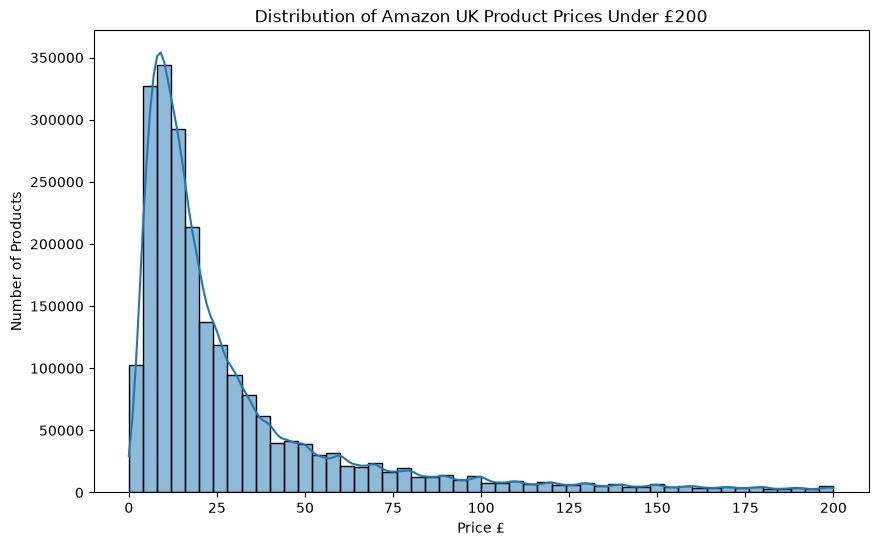

In [26]:
price_under_200 = df[df["price"] <= 200]

plt.figure(figsize=(10, 6))

sns.histplot(
    data=price_under_200,
    x="price",
    bins=50,
    kde=True
)

plt.title("Distribution of Amazon UK Product Prices Under £200")
plt.xlabel("Price £")
plt.ylabel("Number of Products")

plt.show()

In [27]:
kde=True

In [28]:
# Finding: The original histogram is difficult to interpret because a small number of extremely expensive products extend the price range to approximately £100,000. This compresses the majority of products into the lower end of the chart. A second histogram focusing on products priced at £200 or below provides a clearer view of the main price distribution. The results indicate that most products are concentrated at relatively low price points, while the overall distribution has a long right tail caused by high priced products.

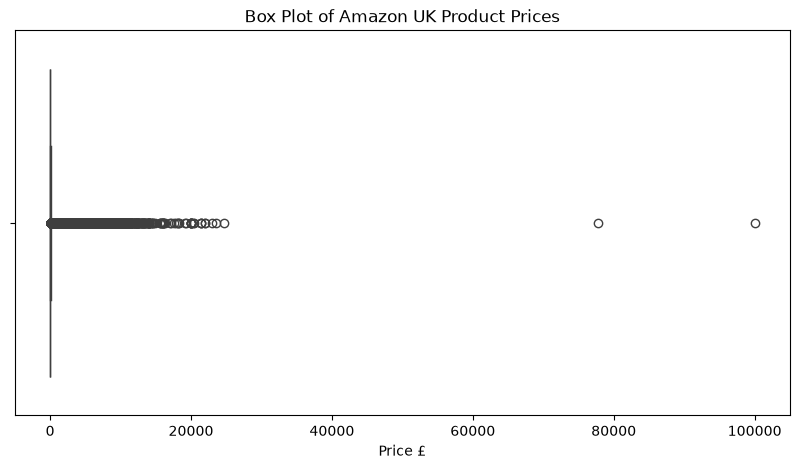

In [29]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="price"
)

plt.title("Box Plot of Amazon UK Product Prices")
plt.xlabel("Price £")

plt.show()

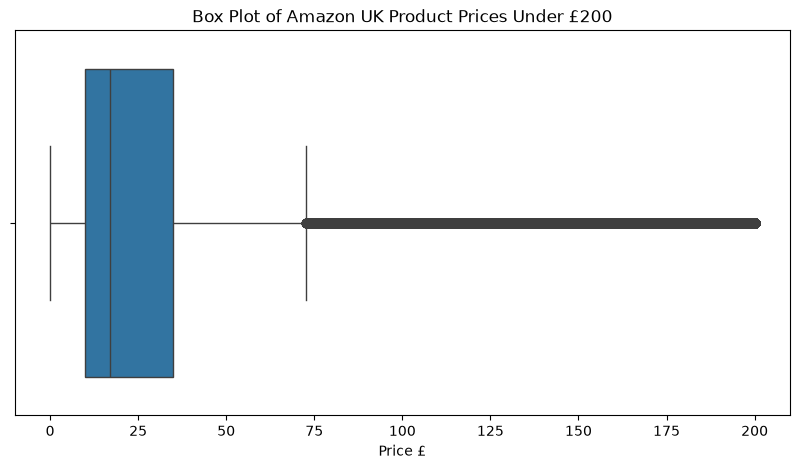

In [30]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=price_under_200,
    x="price"
)

plt.title("Box Plot of Amazon UK Product Prices Under £200")
plt.xlabel("Price £")

plt.show()

In [31]:
#Finding: The box plot confirms that Amazon UK product prices contain numerous high price outliers. Most products are concentrated at relatively low prices, while a smaller number of expensive products extend far beyond the typical price range. This explains the large £100,000 range, the high standard deviation of £345.61, and why the mean price of £89.24 is substantially higher than the median price of £19.09.

In [32]:
### Part 3: Unpacking Product Ratings

# Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

In [33]:
 #Measures of Centrality**:
    # Calculate the mean, median, and mode for the `rating` of products.
    # How do customers generally rate products? Is there a common trend?

mean_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()[0]

print("Mean Rating:", round(mean_rating, 2))
print("Median Rating:", round(median_rating, 2))
print("Mode Rating:", round(mode_rating, 2))


Mean Rating: 2.15
Median Rating: 0.0
Mode Rating: 0.0


In [34]:
df["stars"].value_counts().sort_index()

stars
0.0    1225641
1.0       8484
1.1          3
1.2         23
1.3         78
1.4        149
1.5        404
1.6        147
1.7        177
1.8        249
1.9        300
2.0       3901
2.1        540
2.2        602
2.3        734
2.4       1060
2.5       2103
2.6       1579
2.7       2104
2.8       2306
2.9       3341
3.0      12819
3.1       4679
3.2       5771
3.3       8269
3.4      10355
3.5      14673
3.6      16219
3.7      21137
3.8      27876
3.9      36555
4.0      66089
4.1      65115
4.2      86871
4.3     112564
4.4     136165
4.5     151577
4.6     136995
4.7      94566
4.8      41858
4.9      11081
5.0     128492
Name: count, dtype: int64

In [35]:
zero_ratings = (df["stars"] == 0).sum()
zero_percentage = (df["stars"] == 0).mean() * 100

print("Products with 0 stars:", zero_ratings)
print("Percentage with 0 stars:", round(zero_percentage, 2), "%")

Products with 0 stars: 1225641
Percentage with 0 stars: 50.16 %


In [36]:
df[df["stars"] == 0][["stars", "reviews"]].head(10)

,stars,reviews
25,0.0,0
90,0.0,0
97,0.0,0
246,0.0,0
254,0.0,0
332,0.0,0
372,0.0,0
377,0.0,0
434,0.0,0
445,0.0,0


In [37]:
df[df["stars"] == 0]["reviews"].value_counts().head()

reviews
0    1225641
Name: count, dtype: int64

In [38]:
rated_products = df[df["stars"] > 0]

In [39]:
rated_products.shape

(1218010, 9)

In [40]:
mean_rating = rated_products["stars"].mean()
median_rating = rated_products["stars"].median()
mode_rating = rated_products["stars"].mode()[0]

print("Mean Rating:", round(mean_rating, 2))
print("Median Rating:", round(median_rating, 2))
print("Mode Rating:", round(mode_rating, 2))

Mean Rating: 4.32
Median Rating: 4.4
Mode Rating: 4.5


In [41]:
# Finding: Customers generally rate products positively. Among products with actual customer ratings, the average rating is 4.32 stars, the median is 4.40 stars, and the most common rating is 4.50 stars. Since all three measures are above 4 stars, customer ratings are strongly concentrated toward the higher end of the rating scale.

In [42]:
# Measures of Dispersion**:
    # Determine the variance, standard deviation, and interquartile range for product `rating`.
    # Are the ratings consistent, or is there a wide variation in customer feedback?

rating_variance = rated_products["stars"].var()
rating_std = rated_products["stars"].std()

q1_rating = rated_products["stars"].quantile(0.25)
q3_rating = rated_products["stars"].quantile(0.75)
rating_iqr = q3_rating - q1_rating

print("Variance:", round(rating_variance, 2))
print("Standard Deviation:", round(rating_std, 2))
print("Q1:", round(q1_rating, 2))
print("Q3:", round(q3_rating, 2))
print("IQR:", round(rating_iqr, 2))

Variance: 0.31
Standard Deviation: 0.56
Q1: 4.1
Q3: 4.6
IQR: 0.5


In [43]:
# Finding: Customer ratings show relatively low variation. The standard deviation is 0.56 stars, while the middle 50 percent of rated products fall between 4.1 and 4.6 stars, giving an IQR of only 0.5. This indicates that customer feedback is fairly consistent and concentrated toward high ratings.

In [44]:
# Shape of the Distribution**:
    # Calculate the skewness and kurtosis for the `rating` column. 
    # Are the ratings normally distributed, or do they lean towards higher or lower values?
rating_skewness = rated_products["stars"].skew()
rating_kurtosis = rated_products["stars"].kurt()

print("Skewness:", round(rating_skewness, 2))
print("Kurtosis:", round(rating_kurtosis, 2))

Skewness: -2.38
Kurtosis: 9.78


In [45]:
# Finding: The rating distribution has a skewness of 2.38 negative, indicating a strong negative or left skew. Ratings are concentrated toward higher values, with a tail extending toward lower ratings. The kurtosis of 9.78 indicates that the distribution is substantially more peaked and has heavier tails than a normal distribution. Therefore, customer ratings are not normally distributed.

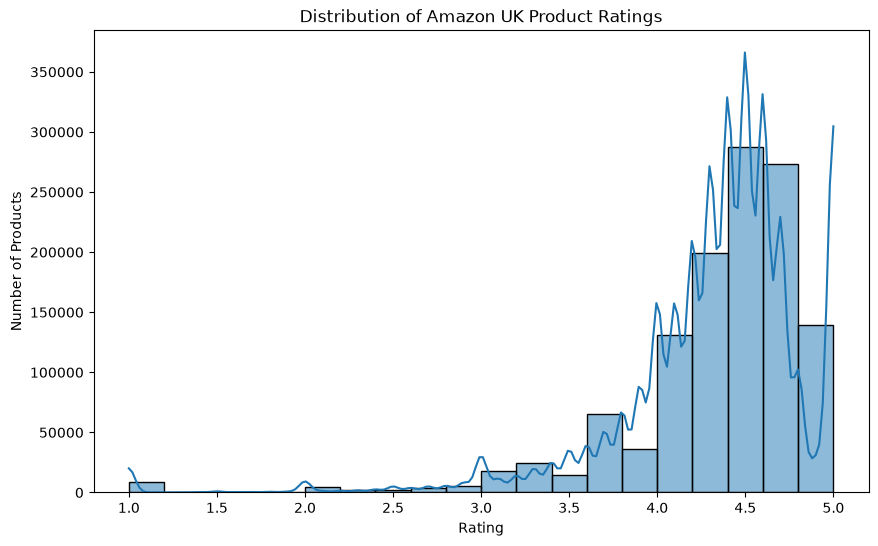

In [46]:
#Visualizations**:
    # Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

plt.figure(figsize=(10, 6))

sns.histplot(
    data=rated_products,
    x="stars",
    bins=20,
    kde=True
)

plt.title("Distribution of Amazon UK Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")

plt.show()

In [48]:
#Finding: The histogram shows that customer ratings are heavily concentrated toward the higher end of the scale, particularly between 4 and 5 stars. The most common rating is 4.5 stars. The longer tail toward lower ratings confirms the strong negative skew identified by the skewness calculation. Overall, customers tend to rate products positively, although a relatively small number of products receive substantially lower ratings.

In [ ]:
#Summary of Findings

The Amazon UK product dataset shows clear differences in listing frequency, pricing, and customer ratings.

For product categories, Sports & Outdoors is by far the most frequently listed category, with 836,265 products. The next leading categories each have around 19,000 listings. This shows that the dataset is heavily concentrated in Sports & Outdoors. From a business perspective, this suggests a particularly large product assortment and potentially greater seller competition in this category. Listing frequency, however, should not be interpreted directly as customer demand or sales performance.

Product prices are strongly skewed toward lower values. The mean price is £89.24, while the median is £19.09 and the most common price is £9.99. The large difference between these measures indicates that a relatively small number of very expensive products increase the overall average. The middle 50 percent of products are priced between £9.99 and £45.99, with an interquartile range of £36. The histogram and box plot also confirm the presence of extreme high price outliers.

Customer ratings require additional consideration because 50.16 percent of the products have zero stars and zero reviews. These products were treated as unrated rather than genuinely receiving zero star ratings. Among products with actual customer ratings, the average rating is 4.32 stars, the median is 4.40, and the most common rating is 4.50. The standard deviation of 0.56 and interquartile range of 0.50 indicate relatively consistent customer feedback. The rating distribution has a skewness of negative 2.38, showing that ratings are concentrated toward the higher end, with relatively fewer low rated products. The kurtosis of 9.78 also shows that the rating distribution differs substantially from a normal distribution.

Overall, the analysis indicates that Amazon UK listings in this dataset are highly concentrated in one major category, most products are positioned at relatively affordable price points despite the presence of extreme high priced products, and customer ratings are generally positive among products that have received reviews.